# Global and local convergence

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/integrix/blob/main/docs/notebooks/theory_convergence.ipynb)

This notebook is the figure for [Global and local](../theory/03_global_and_local.md). We integrate two zonal-mean fields over $\mu = \sin \phi \in [-1, 1]$, where the area of the sphere is uniform in $\mu$, with a global rule (Gauss–Legendre) and a local one (the composite trapezoid rule), and plot the error against the number of nodes $N$.

**What you'll learn:**

1. A global rule converges spectrally on a smooth field, $O(\rho^{-2N})$, while a local rule converges algebraically, $O(h^2)$ for the trapezoid rule.
2. A kink (a sea-ice edge) brings the global rule down to an algebraic rate too.
3. Both rules are the same call, `rule.integrate(weights, samples)`, with different weights.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "integrix @ git+https://github.com/jejjohnson/integrix@main",
        ],
        check=True,
    )

In [2]:
import warnings


warnings.filterwarnings("ignore", message=r".*IProgress.*")

import jax


jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from functax import quad
from scipy.special import erf

from integrix import rule

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p numpy,jax,matplotlib,integrix")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

numpy     : 2.4.4
jax       : 0.12.0.1
matplotlib: 3.11.2
integrix  : 0.0.5

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## Two fields on the sphere

The smooth field is a band of tropical moisture, $f_\text{band}(\mu) = e^{-\mu^2 / (2 \cdot 0.3^2)}$, whose integral comes from the error function. The rough field is a sea-ice fraction, $f_\text{ice}(\mu) = \max(0, |\mu| - 0.8)$, which is zero equatorward of about 53° and has a kink at each ice edge; its integral is exactly $0.04$.

In [4]:
def band(mu):
    """f_band(μ) = exp(−μ²/(2 · 0.3²))."""
    return jnp.exp(-(mu**2) / (2.0 * 0.3**2))


def ice(mu):
    """f_ice(μ) = max(0, |μ| − 0.8)."""
    return jnp.maximum(0.0, jnp.abs(mu) - 0.8)


def trapezoid(n_nodes):
    """functax's trapezoid rule on equally spaced nodes in [−1, 1]."""
    nodes = jnp.linspace(-1.0, 1.0, n_nodes)
    return nodes, quad.trapezoid(nodes).weights


def gauss_legendre(n_nodes):
    """functax's Gauss–Legendre nodes and weights on [−1, 1]."""
    nodes, weights = quad.gauss_legendre(n_nodes)
    return jnp.asarray(nodes), jnp.asarray(weights)


exact = {
    "band": 0.3 * np.sqrt(2.0 * np.pi) * erf(1.0 / (0.3 * np.sqrt(2.0))),
    "ice": 0.04,
}
fields = {"band": band, "ice": ice}
rules = {"Gauss–Legendre (global)": gauss_legendre, "trapezoid (local)": trapezoid}

## The sweep

Every estimate is the same call, $\hat{I}_N = \sum_n w_n f(\mu_n)$, with the weights of one rule or the other.

In [5]:
node_counts = np.unique(np.round(np.geomspace(3, 256, 40)).astype(int))
errors = {}
for field_name, field in fields.items():
    for rule_name, make_rule in rules.items():
        sweep = []
        for n_nodes in node_counts:
            nodes, weights = make_rule(int(n_nodes))
            estimate = rule.integrate(weights, field(nodes)).value
            sweep.append(abs(float(estimate) - exact[field_name]))
        errors[field_name, rule_name] = np.maximum(np.array(sweep), 1e-17)

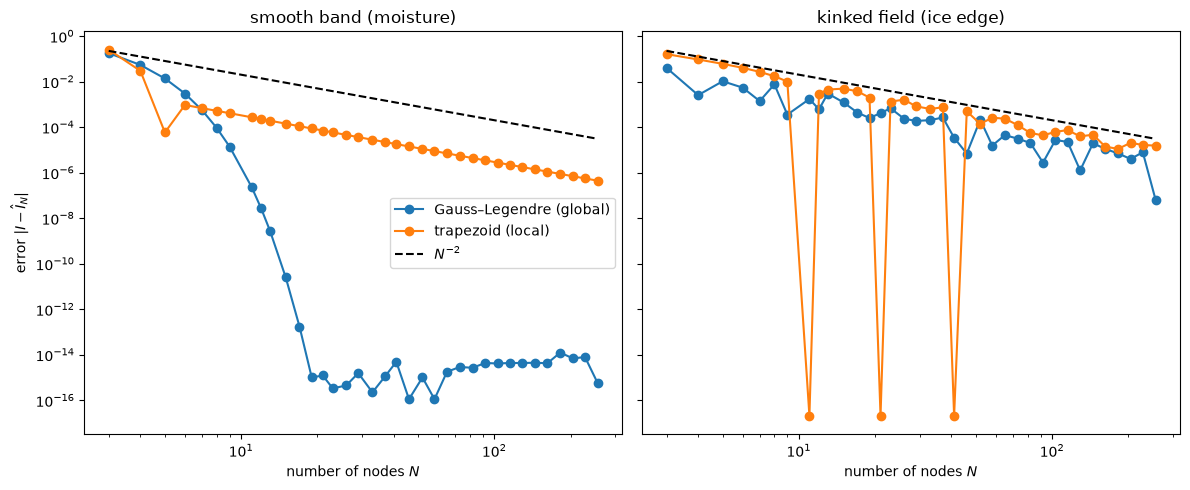

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
titles = {"band": "smooth band (moisture)", "ice": "kinked field (ice edge)"}
for ax, field_name in zip(axes, fields, strict=True):
    for rule_name in rules:
        ax.loglog(node_counts, errors[field_name, rule_name], "o-", label=rule_name)
    reference = 2.0 * node_counts.astype(float) ** -2.0
    ax.loglog(node_counts, reference, "k--", label=r"$N^{-2}$")
    ax.set_title(titles[field_name])
    ax.set_xlabel("number of nodes $N$")
axes[0].set_ylabel(r"error $|I - \hat{I}_N|$")
axes[0].legend()
fig.tight_layout()
plt.show()

On the smooth band the Gauss rule reaches the round-off of float64 at a few tens of nodes, while the trapezoid rule follows the $N^{-2}$ line. On the ice edge both rules follow it, and both are noisy, since the error depends on where the nodes fall relative to the kink. The dips in the trapezoid curve are the node counts that put a node on the edge at $|\mu| = 0.8$, where every tile sees a straight line.

## Summary

- A global rule is spectral only while the integrand is smooth on the whole domain; one kink is enough to make it algebraic.
- A local rule is algebraic everywhere, keeps its error in the tiles that hold the kink, and is exact when a tile edge sits on it.
- Both are weights against samples, so switching rules is switching one array.